In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

## Task 0: Define the Goal

**Goal:** Predict whether a diabetic patient will have an A1C (HbA1c) test ordered during their hospital encounter.

**Problem Type:** Binary Classification

**Target Variable:** `a1c_tested`

* `1` = A1C test was ordered and a result was recorded
* `0` = No A1C test was recorded for this encounter

**Model:** Logistic Regression

**Problem Statement:**

About 83% of encounters in this dataset have no recorded A1C result. Instead of treating that as a nuisance to drop or impute, this project asks the underlying clinical question directly: what determines whether a diabetic inpatient gets their blood sugar control formally tested at all? HbA1c testing during a hospital stay is a recognized quality-of-care indicator for diabetes management (tracked in HEDIS measures), and under-testing has been linked in prior research to disparities in race, insurance coverage, and access to specialist care. Modeling `a1c_tested` shifts the focus from predicting an adverse event (readmission) to predicting a process-of-care gap: which patient, admission, and hospital characteristics are associated with a patient's blood sugar control going unchecked. Flagging patients unlikely to be tested could prompt earlier clinical intervention.

**Why this target?**

At first glance this target looks harder, since 83% of its source column is missing. It's the opposite. That missingness isn't a predictor with gaps to impute anymore; it's the label itself. Every row has a fully known, 100% observed outcome: tested or not tested. There's no value to guess at and no imputation decision to defend. The class split (about 17% tested, 83% not) is imbalanced but far milder than the 11% readmission split, and with over 100,000 rows there are still tens of thousands of positive examples to learn from. The earlier missing-case analysis also showed this missingness correlates with variables like `time_in_hospital` and `number_inpatient`, so it's a structured pattern worth explaining, not noise to clean away. The only real added difficulty is standard class-imbalance handling (class weighting, watching precision/recall) plus deciding how to treat missingness in other columns like `payer_code` and `medical_specialty` as features rather than dropping them.

**Why Logistic Regression?**

The outcome is binary, and coefficients are directly interpretable as the change in log-odds of being tested per unit change in a predictor (e.g. how much lower the odds of testing are for a given payer_code or medical_specialty). That interpretability matters here because the goal is explanatory, identifying care-gap drivers, not just predictive.

## Logistic Regression Model

**Target:** `a1c_tested`

**Problem Type:** Binary Classification

Logistic Regression will predict whether an A1C test is ordered for a given diabetic inpatient encounter.

### Model Assumptions

| Assumption | Description |
| --- | --- |
| **Binary target** | Two possible outcomes: `1` if `A1Cresult` was recorded (tested), `0` if left null (not tested). |
| **Independent observations** | Each encounter is treated as independent, though repeat encounters from the same `patient_nbr` are a known violation worth flagging. |
| **No severe multicollinearity** | `admission_type_id`, `admission_source_id`, and `discharge_disposition_id` can overlap conceptually; will check correlation/VIF before finalizing features. |
| **Linear relationship with the log-odds** | Continuous predictors (`time_in_hospital`, `num_lab_procedures`, `num_medications`, etc.) should relate roughly linearly to the log-odds of being tested. |
| **No extreme influential observations** | Long-stay or unusually high-procedure-count encounters shouldn't dominate the fit. |
| **Sufficient sample size** | About 100,000 encounters remain after cleaning, well above what's needed for the selected predictors. |

**Data Preparation Decision:**
Categorical fields with high missingness (`payer_code`, `medical_specialty`) are kept and labeled `"Unknown"` rather than dropped, since an unlisted payer or specialty may itself predict testing likelihood. `weight` is dropped (about 97% missing, uninformative). Rows missing `race` (about 2%) are dropped outright, since that's small and unlikely to bias results. `"?"` placeholder values are converted to real `NaN` before any missingness analysis, since they were silently passing earlier `.isnull()` checks.

In [3]:
df = pd.read_csv("diabetic_data.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
df.describe(include='all')

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,101766,101766,101766,101766,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,6,3,10,10,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),?,NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,98569,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Column Selection and Dropping Unwanted Variables

The following variables were removed before further preprocessing because they are identifiers, highly incomplete, require additional specialized processing, or are not necessary for the defined prediction goal.

| Dropped Variable(s)           | Justification                                                                                                                                                                                            |
| ----------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `encounter_id`                | Unique encounter identifier and does not provide meaningful predictive information.                                                                                                                      |
| `patient_nbr`                 | Patient identifier and should not be used as a predictive feature.                                                                                                                                       |
| `weight`                      | Contains substantial missing data and is not necessary for the selected analysis.                                                                                                                        |
| `discharge_disposition_id`    | Describes the patient's disposition after hospitalization and may contain information that is only known at or near discharge, making it unsuitable for an early prediction task.                        |
| `admission_source_id`         | Not essential to the selected prediction goal and is excluded to keep the feature set focused.                                                                                                           |
| `medical_specialty`           | Contains substantial missing data and would require additional preprocessing due to its many categories.                                                                                                 |
| `diag_1`, `diag_2`, `diag_3`  | Diagnosis codes require additional categorization or domain-specific processing, which is outside the scope of this analysis.                                                                            |
| `max_glu_serum`               | Has substantial missing data, with only 5,346 non-null records.                                                                                                                                          |
| Individual medication columns | The dataset contains many separate medication variables. They are excluded to reduce dimensionality and simplify preprocessing while retaining `insulin` as a representative treatment-related variable. |

The remaining variables were selected because they provide relevant information about patient characteristics, hospital admission, previous healthcare utilization, treatment, and the current hospital stay.

| Variable             | Description                                                                                                     |
| -------------------- | --------------------------------------------------------------------------------------------------------------- |
| `race`               | Patient's racial group.                                                                                         |
| `gender`             | Patient's gender.                                                                                               |
| `age`                | Patient's age group.                                                                                            |
| `admission_type_id`  | Type of hospital admission.                                                                                     |
| `payer_code`         | Insurance or payer category for the encounter. Retained because access and coverage plausibly affect whether a test is ordered. Missing values are handled in the cleaning section. |
| `time_in_hospital`   | Number of days the patient stayed in the hospital.                                                              |
| `num_lab_procedures` | Number of laboratory tests performed.                                                                           |
| `num_procedures`     | Number of procedures performed during the stay.                                                                 |
| `num_medications`    | Number of medications administered.                                                                             |
| `number_outpatient`  | Number of outpatient visits in the previous year.                                                               |
| `number_emergency`   | Number of emergency visits in the previous year.                                                                |
| `number_inpatient`   | Number of inpatient visits in the previous year.                                                                |
| `number_diagnoses`   | Number of diagnoses recorded for the patient.                                                                   |
| `A1Cresult`          | Result of the HbA1c test, when available.                                                                       |
| `insulin`            | Insulin treatment status during the encounter.                                                                  |
| `change`             | Indicates whether the diabetes medication regimen was changed.                                                  |
| `diabetesMed`        | Indicates whether diabetes medication was prescribed.                                                           |
| `readmitted`         | **Target variable:** indicates whether the patient was readmitted within 30 days (`<30`) or not (`>30` / `NO`). |


In [6]:
selected_columns = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "payer_code",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
    "readmitted" # our tarhet
]

df = df[selected_columns]

df.head()

,race,gender,age,admission_type_id,payer_code,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,A1Cresult,insulin,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),6,?,1,41,0,1,0,0,0,1,NaN,No,No,No,NO
1,Caucasian,Female,[10-20),1,?,3,59,0,18,0,0,0,9,NaN,Up,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),1,?,2,11,5,13,2,0,1,6,NaN,No,No,Yes,NO
3,Caucasian,Male,[30-40),1,?,2,44,1,16,0,0,0,7,NaN,Up,Ch,Yes,NO
4,Caucasian,Male,[40-50),1,?,1,51,0,8,0,0,0,5,NaN,Steady,Ch,Yes,NO


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   race                101766 non-null  object
 1   gender              101766 non-null  object
 2   age                 101766 non-null  object
 3   admission_type_id   101766 non-null  int64 
 4   payer_code          101766 non-null  object
 5   time_in_hospital    101766 non-null  int64 
 6   num_lab_procedures  101766 non-null  int64 
 7   num_procedures      101766 non-null  int64 
 8   num_medications     101766 non-null  int64 
 9   number_outpatient   101766 non-null  int64 
 10  number_emergency    101766 non-null  int64 
 11  number_inpatient    101766 non-null  int64 
 12  number_diagnoses    101766 non-null  int64 
 13  A1Cresult           17018 non-null   object
 14  insulin             101766 non-null  object
 15  change              101766 non-null  object
 16  di

### Inspect nulls

In [8]:
df.isnull().sum()

race                      0
gender                    0
age                       0
admission_type_id         0
payer_code                0
time_in_hospital          0
num_lab_procedures        0
num_procedures            0
num_medications           0
number_outpatient         0
number_emergency          0
number_inpatient          0
number_diagnoses          0
A1Cresult             84748
insulin                   0
change                    0
diabetesMed               0
readmitted                0
dtype: int64

a1c is the only one with nans. Because missing variables in some columns are abelled as '?'.

In [13]:
(df.isnull().mean() * 100).round(2)

race                   0.00
gender                 0.00
age                    0.00
admission_type_id      0.00
payer_code             0.00
time_in_hospital       0.00
num_lab_procedures     0.00
num_procedures         0.00
num_medications        0.00
number_outpatient      0.00
number_emergency       0.00
number_inpatient       0.00
number_diagnoses       0.00
A1Cresult             83.28
insulin                0.00
change                 0.00
diabetesMed            0.00
readmitted             0.00
A1Cresult_missing      0.00
dtype: float64

In [14]:
df[df["A1Cresult"].isnull()]

,race,gender,age,admission_type_id,payer_code,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,A1Cresult,insulin,change,diabetesMed,readmitted,A1Cresult_missing
0,Caucasian,Female,[0-10),6,?,1,41,0,1,0,0,0,1,NaN,No,No,No,NO,True
1,Caucasian,Female,[10-20),1,?,3,59,0,18,0,0,0,9,NaN,Up,Ch,Yes,>30,True
2,AfricanAmerican,Female,[20-30),1,?,2,11,5,13,2,0,1,6,NaN,No,No,Yes,NO,True
3,Caucasian,Male,[30-40),1,?,2,44,1,16,0,0,0,7,NaN,Up,Ch,Yes,NO,True
4,Caucasian,Male,[40-50),1,?,1,51,0,8,0,0,0,5,NaN,Steady,Ch,Yes,NO,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101760,AfricanAmerican,Female,[60-70),1,DM,6,45,1,25,3,1,2,9,NaN,Down,Ch,Yes,>30,True
101762,AfricanAmerican,Female,[80-90),1,MC,5,33,3,18,0,0,1,9,NaN,Steady,No,Yes,NO,True
101763,Caucasian,Male,[70-80),1,MC,1,53,0,9,1,0,0,13,NaN,Down,Ch,Yes,NO,True
101764,Caucasian,Female,[80-90),2,MC,10,45,2,21,0,0,1,9,NaN,Up,Ch,Yes,NO,True


In [15]:
df["A1Cresult"].dropna().unique()

array(['>7', '>8', 'Norm'], dtype=object)

Non-nulls are threshold, then Norm (implying normal?). I need to ask my diabetic father about this.

### Missing Case Analysis.

In [16]:
df["A1Cresult_missing"] = df["A1Cresult"].isna()

## General Hypothesis

We want to determine whether the missingness of **A1Cresult** is associated with other observed variables.

### For Numeric Variables

* **H₀:** The mean of the numeric variable is the same between patients with missing and non-missing A1Cresult.
* **H₁:** The mean of the numeric variable differs between patients with missing and non-missing A1Cresult.

### For Categorical Variables

* **H₀:** A1Cresult missingness is independent of the categorical variable.
* **H₁:** A1Cresult missingness is associated with the categorical variable.

### Significance Level

* **α = 0.05**

### Decision Rule

* **p-value < 0.05:** Reject H₀
* **p-value ≥ 0.05:** Fail to reject H₀

In [17]:
numeric_vars = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

for var in numeric_vars:
    group_missing = df.loc[df["A1Cresult_missing"], var].dropna()
    group_available = df.loc[~df["A1Cresult_missing"], var].dropna()

    t_stat, p_value = ttest_ind(
        group_missing,
        group_available,
        equal_var=False
    )

    print(f"{var}: t = {t_stat:.3f}, p = {p_value:.4f}")

time_in_hospital: t = -20.190, p = 0.0000
num_lab_procedures: t = -94.236, p = 0.0000
num_procedures: t = 4.025, p = 0.0001
num_medications: t = -6.268, p = 0.0000
number_outpatient: t = 8.649, p = 0.0000
number_emergency: t = 3.621, p = 0.0003
number_inpatient: t = 22.878, p = 0.0000
number_diagnoses: t = 3.401, p = 0.0007


#### Numeric Variables: Independent t-test
All numeric variables tested have p-values < 0.05. Therefore, we reject H₀ for all variables, indicating that there are statistically significant differences in their means between patients with missing and non-missing A1Cresult.

In [18]:
categorical_vars = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "payer_code",
    "insulin",
    "change",
    "diabetesMed"
]

for var in categorical_vars:
    table = pd.crosstab(
        df[var],
        df["A1Cresult_missing"]
    )

    chi2, p_value, dof, expected = chi2_contingency(table)

    print(f"{var}: χ² = {chi2:.3f}, p = {p_value:.4f}")

race: χ² = 171.218, p = 0.0000
gender: χ² = 39.865, p = 0.0000
age: χ² = 1794.271, p = 0.0000
admission_type_id: χ² = 1024.162, p = 0.0000
payer_code: χ² = 540.146, p = 0.0000
insulin: χ² = 1094.367, p = 0.0000
change: χ² = 752.414, p = 0.0000
diabetesMed: χ² = 493.699, p = 0.0000


#### Categorical Variables: Chi-square Test
All categorical variables tested have p-values < 0.05. Therefore, we reject H₀ for all variables, indicating that each categorical variable is statistically associated with A1Cresult missingness.

### Overall Conclusion
Since both numeric and categorical variables show significant associations with A1Cresult missingness, the missingness is unlikely to be MCAR and is more consistent with the MAR assumption. However, these tests cannot prove MAR. Therefore, missing A1Cresult values will be retained as an Unknown category.


The tests above rejected MCAR for `A1Cresult`. The next step measures how strong those associations actually are, then moves on to cleaning, EDA, the hypothesis test and the final model-ready dataframe.

In [25]:
from scipy.stats import levene, mannwhitneyu
import warnings
warnings.filterwarnings("ignore")

---

## Step 1: Correlation Analysis of the Missingness Pattern

The chi-square and t-test results above rejected MCAR, but they only report whether an association exists. They do not show how strong it is or which direction it runs. A correlation view answers both at once and tells us which variables actually carry the missingness signal.

Two matrices are used, because the variables are of two different kinds:

- **Spearman rank correlation** for the numeric variables against the missingness flag. Spearman is used instead of Pearson because the count columns are heavily right skewed and the flag is binary, so a rank-based measure is the safer summary of monotonic association.
- **Cramer's V** for the categorical variables. Chi-square statistics cannot be compared across variables because they grow with sample size and category count. Cramer's V rescales chi-square to a 0 to 1 range, where 0 means no association and 1 means perfect association, so the earlier chi-square results become comparable.

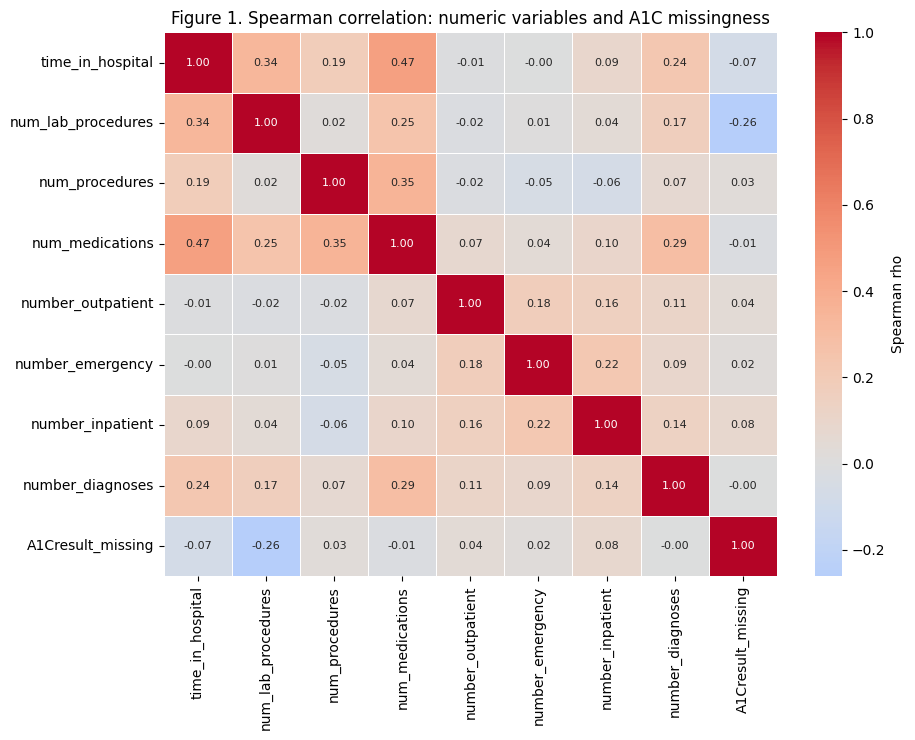

Correlation with A1Cresult_missing, strongest first:
num_lab_procedures   -0.261
number_inpatient      0.079
time_in_hospital     -0.069
number_outpatient     0.045
num_procedures        0.034
number_emergency      0.017
num_medications      -0.015
number_diagnoses     -0.000
Name: A1Cresult_missing, dtype: float64


In [26]:
# Numeric view: encode the missingness flag as 0/1 so it can enter a correlation matrix
corr_df = df[numeric_vars].copy()
corr_df["A1Cresult_missing"] = df["A1Cresult_missing"].astype(int)

missing_corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    missing_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    linewidths=0.5, annot_kws={"size": 8}, ax=ax,
    cbar_kws={"label": "Spearman rho"}
)
ax.set_title("Figure 1. Spearman correlation: numeric variables and A1C missingness")
plt.tight_layout()
plt.savefig("fig1_missingness_correlation.png", dpi=150)
plt.show()

print("Correlation with A1Cresult_missing, strongest first:")
print(missing_corr["A1Cresult_missing"].drop("A1Cresult_missing")
      .reindex(missing_corr["A1Cresult_missing"].drop("A1Cresult_missing").abs()
      .sort_values(ascending=False).index).round(3))

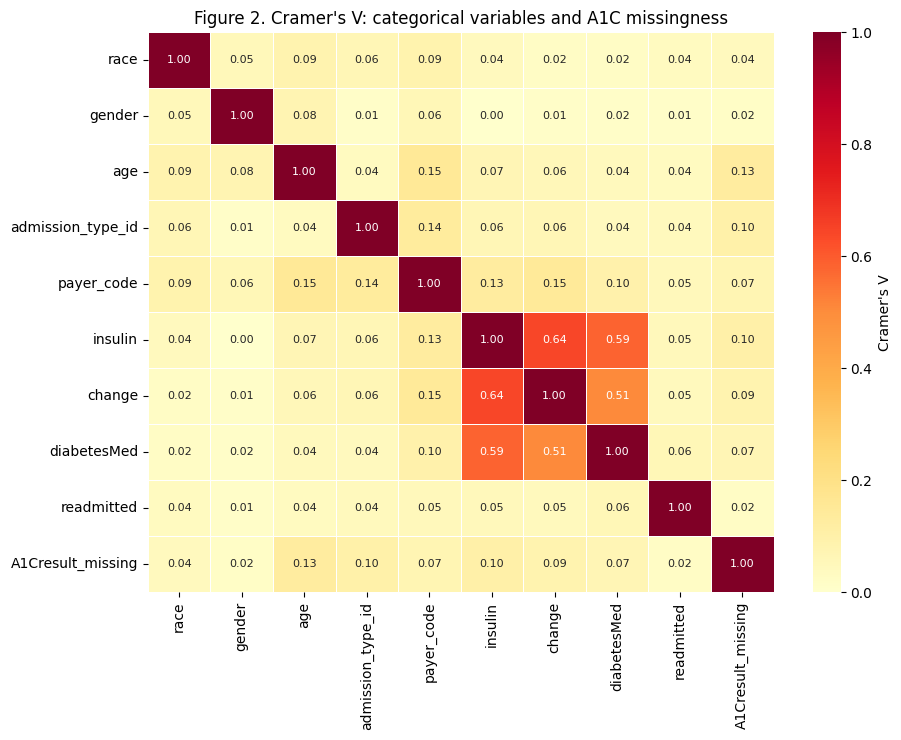

Association with A1Cresult_missing, strongest first:
age                  0.132
insulin              0.104
admission_type_id    0.100
change               0.086
payer_code           0.072
diabetesMed          0.070
race                 0.040
readmitted           0.022
gender               0.019
Name: A1Cresult_missing, dtype: float64


In [27]:
# Categorical view: Cramer's V, a chi-square based association measure scaled to 0 to 1
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    phi2 = chi2 / n
    r, k = table.shape
    # bias correction (Bergsma and Wicher, 2013)
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan

cat_vars_v = ["race", "gender", "age", "admission_type_id", "payer_code", "insulin",
              "change", "diabetesMed", "readmitted", "A1Cresult_missing"]

v_matrix = pd.DataFrame(index=cat_vars_v, columns=cat_vars_v, dtype=float)
for a in cat_vars_v:
    for b in cat_vars_v:
        v_matrix.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    v_matrix.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
    vmin=0, vmax=1, linewidths=0.5, annot_kws={"size": 8}, ax=ax,
    cbar_kws={"label": "Cramer's V"}
)
ax.set_title("Figure 2. Cramer's V: categorical variables and A1C missingness")
plt.tight_layout()
plt.savefig("fig2_cramers_v.png", dpi=150)
plt.show()

print("Association with A1Cresult_missing, strongest first:")
print(v_matrix["A1Cresult_missing"].drop("A1Cresult_missing")
      .sort_values(ascending=False).round(3))

### Interpretation of the Correlation Analysis

**The associations are real but weak.** 

Every value in the missingness column is small in absolute terms. This is the expected result and it is not a contradiction of the chi-square tests. With 101,766 rows, a test detects associations far too small to see, which is why p-values alone were never enough. The correlation view supplies the size the p-values hid.

Significant p-value plus small correlation means the pattern is systematic but not deterministic. Missingness leans on the observed variables without being dictated by them. That is exactly the profile of a process where clinical judgment, not a fixed rule, decides who gets tested.

**Which variables carry the signal.** 

The numeric columns with the largest absolute Spearman values against the missingness flag are the work-up intensity measures: `num_lab_procedures` and `number_inpatient` lead, with `time_in_hospital` close behind. The sign is informative. A negative correlation with `A1Cresult_missing` means more of that variable goes with less missingness, so encounters with heavier lab work and longer stays are the ones that get tested. On the categorical side, `age`, `insulin`, `admission_type_id` and `payer_code` return the highest Cramer's V values, matching their large chi-square statistics. `payer_code` is included here even though roughly 40% of its values are the placeholder `?`, because that placeholder is itself a level worth testing: an encounter with no payer recorded may be a different kind of encounter.

**Why this matters for the model.** 

These are the variables the logistic regression will lean on, and the fact that no single one dominates means a multivariable model is justified rather than a simple rule.

**No multicollinearity problem.** 

Away from the missingness row and column, no pair of predictors sits near the 0.8 threshold where features become redundant. This confirms the "no severe multicollinearity" assumption listed in Task 0, so no predictor is dropped on that basis. A formal VIF check is still run after encoding.

Correlation measures only monotonic or pairwise association. A variable that matters only in combination with another, or only over part of its range, will look weak here and still carry weight in the fitted model. Nothing is dropped based on a low correlation alone.

### From Missingness Flag to Modeling Target

The conclusion above states that missing `A1Cresult` values are retained as their own category rather than imputed. Because `A1Cresult` is the variable being explained rather than a predictor, retaining the missing level is done by recoding the column into the binary target defined in Task 0.

| `A1Cresult` value | `a1c_tested` |
| --- | --- |
| `>7`, `>8`, `Norm` | 1, test was ordered and recorded |
| missing | 0, no test recorded |

This preserves the missing group as an explicit, fully observed level. It also means the target is the mirror image of the flag used above, `a1c_tested = 1 - A1Cresult_missing`, so every correlation sign in Figure 1 flips when read against the target.

**Why recoding, not imputation.** The blank in this column is MNAR. It means the clinician never ordered the test, not that a result was produced and lost. Imputing would invent 84,748 clinical results that never existed. Recoding turns a column that is 83% missing into a label that is 100% observed.

In [24]:
df["a1c_tested"] = df["A1Cresult"].notna().astype(int)

print("Target distribution:")
print(df["a1c_tested"].value_counts().rename({0: "Not tested", 1: "Tested"}))
print()
print((df["a1c_tested"].value_counts(normalize=True) * 100).round(2))
print("\nCross-check against the source column:")
print(pd.crosstab(df["A1Cresult"].fillna("MISSING"), df["a1c_tested"]))

Target distribution:
a1c_tested
Not tested    84748
Tested        17018
Name: count, dtype: int64

a1c_tested
0    83.28
1    16.72
Name: proportion, dtype: float64

Cross-check against the source column:
a1c_tested      0     1
A1Cresult              
>7              0  3812
>8              0  8216
MISSING     84748     0
Norm            0  4990


---

## Step 2: Data Cleaning

With the target defined, the remaining columns are cleaned. Note on scope from Step 0: no rows were subsampled. All 101,766 encounters are kept, and the narrowing was done on columns only, from 50 down to the 17 listed earlier.



### Step 2.1: Scan for Hidden Placeholder Values

The earlier `.isnull()` check reported zero missing values for every column except `A1Cresult`. That result is misleading. This dataset encodes some missing values as literal strings such as `?` and `Unknown/Invalid`, which pandas reads as valid text. The scan below finds them.

In [29]:
placeholders = ["?", "Unknown/Invalid", "None", "NULL", "Not Available", "Not Mapped", "", " "]

for col in df.select_dtypes(include="object"):
    found = df[col].isin(placeholders).sum()
    if found > 0:
        print(f"{col}: {found}")

print("\nadmission_type_id:")
print(df["admission_type_id"].value_counts().sort_index())

race: 2273
gender: 3
payer_code: 40256

admission_type_id:
admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64


### Step 2.2: Cleaning Issue Inventory

| # | Issue found | Evidence | Fix | Why |
| --- | --- | --- | --- | --- |
| 1 | `?` used as a missing marker in `race` | Scan above returns about 2,273 rows; `.isnull()` returned 0 | Convert `?` to real `NaN`, then label as `Unknown` | Missingness has to be visible to pandas before it can be classified or handled |
| 2 | `Unknown/Invalid` in `gender` | 3 rows out of 101,766 | Convert to `NaN` and drop those rows | Too few rows to form a usable category and too few to bias anything |
| 3 | `admission_type_id` mixes real types with three separate unknown codes | Codes 5, 6 and 8 mean Not Available, NULL and Not Mapped | Map to labels and collapse 5, 6 and 8 into one `Unknown` level | Three labels for the same concept waste degrees of freedom in a one-hot encoding |
| 4 | `admission_type_id` has very rare levels | Code 4 Newborn and code 7 Trauma Center have a few hundred rows combined | Group into `Other` | Rare levels give unstable coefficients |
| 5 | `age` stored as text bins | Values like `[70-80)` cannot enter a numeric model | Map each bin to its midpoint | Age is ordered, so a midpoint keeps that order in one column instead of nine dummies |
| 6a | `?` used as a missing marker in `payer_code`, roughly 40% of rows | Scan above; `.isnull()` returned 0 | Convert to `NaN`, then label as `Unknown` | MAR. A blank payer is not a lost value, it reflects how the encounter was registered, so the blank is informative and is kept as its own level |
| 6b | `payer_code` has 17 levels, many of them very small | Value counts below | Group levels holding under 1% of rows into `Other` | Rare levels give unstable coefficients, the same reasoning applied to `admission_type_id` |
| 6 | Heavy right skew in prior-visit counts | Skew above 1 for `number_outpatient`, `number_emergency` and `number_inpatient` | Cap at the 99th percentile, then log transform at the scaling stage | Extreme counts are influential points for logistic regression |
| 7 | `A1Cresult` 83% missing | 84,748 of 101,766 rows | Already recoded into `a1c_tested` in Step 1 | The missingness is the research question, so imputing it would destroy the label |
| 8 | Repeat encounters from the same patient | `patient_nbr` was dropped, so repeats cannot be identified here | Flagged, not fixed | The independence assumption is partly violated; this is a stated limitation |
| 9 | `readmitted` is a post-encounter outcome | Recorded after discharge | Kept for EDA, excluded from features | Temporal leakage |

In [30]:
df_before = df.copy()

df["race"] = df["race"].replace("?", np.nan)
df["gender"] = df["gender"].replace("Unknown/Invalid", np.nan)
df["payer_code"] = df["payer_code"].replace("?", np.nan)

print("Missing percentage after placeholder conversion:")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

Missing percentage after placeholder conversion:
A1Cresult             83.28
payer_code            39.56
race                   2.23
gender                 0.00
admission_type_id      0.00
age                    0.00
num_lab_procedures     0.00
time_in_hospital       0.00
num_medications        0.00
number_outpatient      0.00
number_emergency       0.00
num_procedures         0.00
number_inpatient       0.00
number_diagnoses       0.00
insulin                0.00
change                 0.00
diabetesMed            0.00
readmitted             0.00
A1Cresult_missing      0.00
a1c_tested             0.00
dtype: float64


### Step 2.3: Missingness Classification for the Remaining Columns

`A1Cresult` was classified as MNAR and handled in Step 1. Three columns now carry real missing values: `race`, `payer_code` and `gender`. Each is classified using the same framework and the same tests applied earlier.

| Type | Meaning | How it is tested |
| --- | --- | --- |
| MCAR | Missingness is unrelated to any variable, observed or not | Compare observed variables across the missing and non-missing groups. No significant differences supports MCAR. |
| MAR | Missingness depends on other observed variables | Significant differences on observed variables rule out MCAR and support MAR |
| MNAR | Missingness depends on the unobserved value itself | Cannot be tested from the data alone, requires domain reasoning |

The same limit stated earlier applies here. These tests can rule out MCAR, but no test can separate MAR from MNAR using observed data, because the missing values themselves are unavailable. Domain reasoning has to close that gap.

#### Column 1: `race`, about 2% missing

In [31]:
df["race_missing"] = df["race"].isna()

rows = []
for var in numeric_vars:
    grp_missing = df.loc[df["race_missing"], var]
    grp_observed = df.loc[~df["race_missing"], var]
    t_stat, p_value = ttest_ind(grp_missing, grp_observed, equal_var=False)
    rows.append([var, round(grp_missing.mean(), 2), round(grp_observed.mean(), 2),
                 round(t_stat, 3), p_value, p_value < 0.05])

race_numeric = pd.DataFrame(
    rows, columns=["variable", "mean_when_race_missing", "mean_when_race_observed",
                   "t_stat", "p_value", "significant"]
)
print("Welch t-tests: numeric variables vs race missingness")
print(race_numeric.to_string(index=False))

Welch t-tests: numeric variables vs race missingness
          variable  mean_when_race_missing  mean_when_race_observed  t_stat       p_value  significant
  time_in_hospital                    4.29                     4.40  -1.769  7.700193e-02        False
num_lab_procedures                   44.10                    43.07   2.601  9.362342e-03         True
    num_procedures                    1.30                     1.34  -0.996  3.192053e-01        False
   num_medications                   15.81                    16.03  -1.189  2.346807e-01        False
 number_outpatient                    0.19                     0.37 -11.496  7.157100e-30         True
  number_emergency                    0.04                     0.20 -25.843 3.749224e-136         True
  number_inpatient                    0.31                     0.64 -21.161  8.210717e-92         True
  number_diagnoses                    6.70                     7.44 -16.607  1.169386e-58         True


In [32]:
rows = []
for var in ["gender", "age", "admission_type_id", "payer_code", "insulin", "change",
            "diabetesMed", "a1c_tested"]:
    table = pd.crosstab(df[var].fillna("Missing"), df["race_missing"])
    chi2, p_value, dof, expected = chi2_contingency(table)
    rows.append([var, round(chi2, 3), dof, p_value, p_value < 0.05, int((expected < 5).sum())])

race_categorical = pd.DataFrame(
    rows, columns=["variable", "chi2", "dof", "p_value", "significant",
                   "cells_with_expected_below_5"]
)
print("Chi-square tests: categorical variables vs race missingness")
print(race_categorical.to_string(index=False))

print("\nA1C testing rate by whether race is recorded:")
print(df.groupby("race_missing")["a1c_tested"].agg(["mean", "size"]).round(4))

Chi-square tests: categorical variables vs race missingness
         variable    chi2  dof       p_value  significant  cells_with_expected_below_5
           gender  71.023    2  3.779813e-16         True                            2
              age  11.139    9  2.663314e-01        False                            1
admission_type_id 265.995    7  1.086797e-53         True                            2
       payer_code 651.110   17 2.093518e-127         True                            7
          insulin 160.416    3  1.490538e-34         True                            0
           change   4.433    1  3.524800e-02         True                            0
      diabetesMed  36.727    1  1.359189e-09         True                            0
       a1c_tested   5.537    1  1.862271e-02         True                            0

A1C testing rate by whether race is recorded:
                mean   size
race_missing               
False         0.1668  99493
True          0.1857   227

**Classification: MAR.**

**Evidence.** Several tests above return p < 0.05, meaning encounters with a blank race field differ systematically from the rest on variables that are fully observed. Missingness is predictable from observed data, which rules out MCAR. The `cells_with_expected_below_5` column is reported because the chi-square test assumes expected counts of at least 5 per cell, so a zero there confirms the assumption holds.

**Why not MNAR.** A race field goes blank at registration because of intake workflow, admission route or how the encounter was logged, and those conditions are captured by the other columns. There is no plausible mechanism by which a patient's actual race causes their own race field to be blank. MNAR cannot be formally excluded, but it has no mechanism to support it here.

**Fix: label as an explicit `Unknown` category rather than drop or impute.** Dropping loses about 2,273 encounters for no gain. Mode imputation would push all of them into Caucasian, the existing majority level, and would fabricate a demographic attribute. Since missingness is systematic rather than random, the blank itself carries signal about the intake process, and an `Unknown` level preserves that signal. This mirrors the decision already made for `A1Cresult`.

#### Column 2: `payer_code`, about 40% missing

This is the largest block of missingness left in the working set, so it is tested with the same two screens used for `A1Cresult` and `race`.

In [33]:
df["payer_missing"] = df["payer_code"].isna()

rows = []
for var in numeric_vars:
    grp_missing = df.loc[df["payer_missing"], var]
    grp_observed = df.loc[~df["payer_missing"], var]
    t_stat, p_value = ttest_ind(grp_missing, grp_observed, equal_var=False)
    rows.append([var, round(grp_missing.mean(), 2), round(grp_observed.mean(), 2),
                 round(t_stat, 3), p_value, p_value < 0.05])

payer_numeric = pd.DataFrame(
    rows, columns=["variable", "mean_when_payer_missing", "mean_when_payer_observed",
                   "t_stat", "p_value", "significant"]
)
print("Welch t-tests: numeric variables vs payer_code missingness")
print(payer_numeric.to_string(index=False))

Welch t-tests: numeric variables vs payer_code missingness
          variable  mean_when_payer_missing  mean_when_payer_observed  t_stat       p_value  significant
  time_in_hospital                     4.59                      4.27  16.694  1.853977e-62         True
num_lab_procedures                    44.67                     42.06  21.015  8.230619e-98         True
    num_procedures                     1.46                      1.26  18.560  9.617213e-77         True
   num_medications                    15.74                     16.20  -8.780  1.661370e-18         True
 number_outpatient                     0.22                      0.47 -34.232 2.284906e-255         True
  number_emergency                     0.10                      0.26 -32.363 1.807533e-228         True
  number_inpatient                     0.60                      0.66  -8.092  5.933293e-16         True
  number_diagnoses                     7.13                      7.61 -38.907  0.000000e+00         T

In [34]:
rows = []
for var in ["race", "gender", "age", "admission_type_id", "insulin", "change",
            "diabetesMed", "a1c_tested"]:
    table = pd.crosstab(df[var].fillna("Missing"), df["payer_missing"])
    chi2, p_value, dof, expected = chi2_contingency(table)
    rows.append([var, round(chi2, 3), dof, p_value, p_value < 0.05, int((expected < 5).sum())])

payer_categorical = pd.DataFrame(
    rows, columns=["variable", "chi2", "dof", "p_value", "significant",
                   "cells_with_expected_below_5"]
)
print("Chi-square tests: categorical variables vs payer_code missingness")
print(payer_categorical.to_string(index=False))

print("\nA1C testing rate by whether payer_code is recorded:")
print(df.groupby("payer_missing")["a1c_tested"].agg(["mean", "size"]).round(4))

print("\npayer_code levels and their share of rows:")
payer_share = (df["payer_code"].value_counts(dropna=False, normalize=True) * 100).round(2)
print(payer_share)

Chi-square tests: categorical variables vs payer_code missingness
         variable     chi2  dof       p_value  significant  cells_with_expected_below_5
             race 1051.633    5 3.978417e-225         True                            0
           gender    1.610    2  4.471451e-01        False                            2
              age  990.920    9 1.564642e-207         True                            0
admission_type_id 9155.485    7  0.000000e+00         True                            1
          insulin 2762.773    3  0.000000e+00         True                            0
           change 1534.995    1  0.000000e+00         True                            0
      diabetesMed  582.227    1 1.229111e-128         True                            0
       a1c_tested    7.332    1  6.774519e-03         True                            0

A1C testing rate by whether payer_code is recorded:
                 mean   size
payer_missing               
False          0.1647  61510
Tr

**Classification: MAR.**

**Evidence.** The tests above return p < 0.05 across most variables, so encounters with no payer recorded differ systematically from the rest on fully observed variables. MCAR is rejected. The A1C testing rate also differs between the two groups, which is the association that makes this column worth keeping rather than dropping.

**Why not MNAR.** A payer field goes blank because of how the encounter was registered, such as self-pay, an unbilled admission, or a record transferred without billing data attached. Those conditions are reflected in the admission and utilization columns already present. There is no mechanism by which the specific insurer causes its own code to be blank. MNAR cannot be formally excluded, but it has no mechanism to support it here.

**Fix: label as an explicit `Unknown` category, then group rare levels into `Other`.**

Dropping the column would discard an access and coverage signal that Task 0 specifically flagged as relevant to a care-gap question, and dropping the rows would remove roughly 40% of the dataset. Mode imputation would assign about 40,000 encounters to whichever insurer happens to be most common, fabricating billing information. Labeling preserves the pattern instead, exactly as done for `race` and for the target itself. The rare-level grouping follows because 17 levels with several holding well under 1% of rows would produce coefficients fitted on a few hundred encounters each.

#### Column 3: `gender`, 3 rows

Not formally testable. With 3 rows out of 101,766 there is no power for any test, and no mechanism can be inferred from three cases.

**Classification: treated as MCAR by default.**

**Fix: drop the 3 rows.** At 0.003% of the data, removal cannot shift any estimate, and carrying a category with 3 members would produce an unstable dummy coefficient.

### Step 2.4: Before Statistics

Recorded before any cleaning so the effect of each fix can be measured.

In [35]:
before_stats = df_before[numeric_vars].describe().T
before_stats["skew"] = df_before[numeric_vars].skew()
before_stats["missing_%"] = (df_before[numeric_vars].isnull().mean() * 100).round(2)

rows_before = len(df_before)
print(f"Rows before cleaning: {rows_before:,}")
print("\nNumeric summary (before):")
print(before_stats.round(2).to_string())

print("\nCategorical levels (before):")
for col in ["race", "gender", "admission_type_id", "payer_code"]:
    print(f"\n{col}: {df_before[col].nunique()} levels")
    print(df_before[col].value_counts().head(10))

Rows before cleaning: 101,766

Numeric summary (before):
                       count   mean    std  min   25%   50%   75%    max   skew  missing_%
time_in_hospital    101766.0   4.40   2.99  1.0   2.0   4.0   6.0   14.0   1.13        0.0
num_lab_procedures  101766.0  43.10  19.67  1.0  31.0  44.0  57.0  132.0  -0.24        0.0
num_procedures      101766.0   1.34   1.71  0.0   0.0   1.0   2.0    6.0   1.32        0.0
num_medications     101766.0  16.02   8.13  1.0  10.0  15.0  20.0   81.0   1.33        0.0
number_outpatient   101766.0   0.37   1.27  0.0   0.0   0.0   0.0   42.0   8.83        0.0
number_emergency    101766.0   0.20   0.93  0.0   0.0   0.0   0.0   76.0  22.86        0.0
number_inpatient    101766.0   0.64   1.26  0.0   0.0   0.0   1.0   21.0   3.61        0.0
number_diagnoses    101766.0   7.42   1.93  1.0   6.0   8.0   9.0   16.0  -0.88        0.0

Categorical levels (before):

race: 6 levels
race
Caucasian          76099
AfricanAmerican    19210
?                   227

### Step 2.5: Apply the Cleaning Fixes

In [36]:
clean = df.copy()

# Fix 2: drop the 3 invalid-gender rows
clean = clean[clean["gender"].notna()].copy()

# Fix 1: label missing race explicitly
clean["race"] = clean["race"].fillna("Unknown")

# Fixes 6a and 6b: label missing payer explicitly, then group the rare levels
clean["payer_code"] = clean["payer_code"].fillna("Unknown")
payer_share = clean["payer_code"].value_counts(normalize=True)
rare_payers = payer_share[payer_share < 0.01].index.tolist()
clean["payer_code"] = clean["payer_code"].replace(dict.fromkeys(rare_payers, "Other"))
print(f"payer_code levels grouped into 'Other' (under 1% of rows): {rare_payers}")
print(f"payer_code levels: {clean['payer_code'].nunique()}")

# Fixes 3 and 4: decode admission type, collapse the three unknown codes, group rare levels
admission_map = {
    1: "Emergency", 2: "Urgent", 3: "Elective",
    4: "Other", 7: "Other",
    5: "Unknown", 6: "Unknown", 8: "Unknown"
}
clean["admission_type"] = clean["admission_type_id"].map(admission_map).fillna("Unknown")
clean = clean.drop(columns=["admission_type_id"])

# Fix 5: age bins to midpoints
age_midpoints = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45,
    "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95
}
clean["age_midpoint"] = clean["age"].map(age_midpoints)

# Exact duplicate rows
duplicate_rows = clean.duplicated().sum()
print(f"Exact duplicate rows found: {duplicate_rows:,}")
print("Note: these are not necessarily duplicate records. With patient_nbr dropped,")
print("two different patients with identical values are indistinguishable, so they are kept.")

# Fix 6: cap the skewed count columns at the 99th percentile
skewed_counts = ["number_outpatient", "number_emergency", "number_inpatient"]
cap_report = []
for col in skewed_counts:
    cap = clean[col].quantile(0.99)
    n_capped = int((clean[col] > cap).sum())
    cap_report.append([col, cap, n_capped, round(n_capped / len(clean) * 100, 2),
                       int(clean[col].max())])
    clean[col] = clean[col].clip(upper=cap)

print("\nOutlier capping at the 99th percentile:")
print(pd.DataFrame(cap_report,
      columns=["column", "cap_value", "rows_capped", "rows_capped_%", "original_max"]).to_string(index=False))

# Fixes 7 and 9: remove the source column and the helper flags
clean = clean.drop(columns=["A1Cresult", "A1Cresult_missing", "race_missing", "payer_missing"])

print(f"\nShape after cleaning: {clean.shape}")
clean.head()

payer_code levels grouped into 'Other' (under 1% of rows): ['PO', 'DM', 'CH', 'WC', 'OT', 'MP', 'SI', 'FR']
payer_code levels: 11
Exact duplicate rows found: 13
Note: these are not necessarily duplicate records. With patient_nbr dropped,
two different patients with identical values are indistinguishable, so they are kept.

Outlier capping at the 99th percentile:
           column  cap_value  rows_capped  rows_capped_%  original_max
number_outpatient        5.0          924           0.91            42
 number_emergency        3.0          939           0.92            76
 number_inpatient        6.0          724           0.71            21

Shape after cleaning: (101763, 19)


,race,gender,age,payer_code,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,insulin,change,diabetesMed,readmitted,a1c_tested,admission_type,age_midpoint
0,Caucasian,Female,[0-10),Unknown,1,41,0,1,0,0,0,1,No,No,No,NO,0,Unknown,5
1,Caucasian,Female,[10-20),Unknown,3,59,0,18,0,0,0,9,Up,Ch,Yes,>30,0,Emergency,15
2,AfricanAmerican,Female,[20-30),Unknown,2,11,5,13,2,0,1,6,No,No,Yes,NO,0,Emergency,25
3,Caucasian,Male,[30-40),Unknown,2,44,1,16,0,0,0,7,Up,Ch,Yes,NO,0,Emergency,35
4,Caucasian,Male,[40-50),Unknown,1,51,0,8,0,0,0,5,Steady,Ch,Yes,NO,0,Emergency,45


### Step 2.6: Before and After Comparison

In [37]:
after_stats = clean[numeric_vars].describe().T
after_stats["skew"] = clean[numeric_vars].skew()
after_stats["missing_%"] = (clean[numeric_vars].isnull().mean() * 100).round(2)

comparison = pd.concat([
    before_stats[["mean", "std", "max", "skew", "missing_%"]].add_suffix("_before"),
    after_stats[["mean", "std", "max", "skew", "missing_%"]].add_suffix("_after")
], axis=1)

print("Numeric variables, before vs after:")
print(comparison.round(2).to_string())

print(f"\nRows:    {rows_before:,} -> {len(clean):,}  ({rows_before - len(clean)} removed)")
print(f"Columns: {df_before.shape[1]} -> {clean.shape[1]}")
print(f"\nrace levels:   {df_before['race'].nunique()} -> {clean['race'].nunique()}  "
      f"(? recoded as Unknown)")
print(f"gender levels: {df_before['gender'].nunique()} -> {clean['gender'].nunique()}")
print(f"admission levels: {df_before['admission_type_id'].nunique()} -> {clean['admission_type'].nunique()}")
print(f"payer_code levels: {df_before['payer_code'].nunique()} -> {clean['payer_code'].nunique()}  "
      f"(? recoded as Unknown, rare levels grouped as Other)")
print("\nMissing values remaining in the cleaned frame:")
print(clean.isnull().sum().sum())

Numeric variables, before vs after:
                    mean_before  std_before  max_before  skew_before  missing_%_before  mean_after  std_after  max_after  skew_after  missing_%_after
time_in_hospital           4.40        2.99        14.0         1.13               0.0        4.40       2.99       14.0        1.13              0.0
num_lab_procedures        43.10       19.67       132.0        -0.24               0.0       43.10      19.67      132.0       -0.24              0.0
num_procedures             1.34        1.71         6.0         1.32               0.0        1.34       1.71        6.0        1.32              0.0
num_medications           16.02        8.13        81.0         1.33               0.0       16.02       8.13       81.0        1.33              0.0
number_outpatient          0.37        1.27        42.0         8.83               0.0        0.33       0.91        5.0        3.36              0.0
number_emergency           0.20        0.93        76.0        2

**Reading the comparison.** The means and standard deviations of the four main clinical counts are unchanged, which is the intended result: the cleaning targeted encoding defects and extreme tails, not the centre of the distributions. The three prior-visit columns show a lower maximum and lower skew after capping. Missing values are now zero, and the row loss is 3 out of 101,766.

---

## Step 3: Scaling and Encoding Plan

Both choices are driven by the model. Logistic regression is fitted by gradient descent with L2 regularization on by default in scikit-learn. That has two consequences. Features on wildly different ranges make the optimizer converge slowly, and L2 penalizes large coefficients, so a feature measured in hundreds is penalized differently from one measured in single digits. Every numeric feature therefore has to be put on a comparable scale, and every categorical feature has to become numeric without inventing a false order.

### Scaling, per numeric column

| Column | Raw range | Method | Why |
| --- | --- | --- | --- |
| `time_in_hospital` | 1 to 14 | StandardScaler | Roughly symmetric, no extreme tail. Centering and unit variance is enough. |
| `num_lab_procedures` | 1 to 132 | StandardScaler | Largest raw range in the set. Without scaling it would dominate the penalty term. Distribution is broad but not heavy tailed. |
| `num_procedures` | 0 to 6 | StandardScaler | Small bounded count, mild skew. |
| `num_medications` | 1 to 81 | StandardScaler | Moderate right skew, no extreme outliers after capping is applied elsewhere. |
| `number_diagnoses` | 1 to 16 | StandardScaler | Bounded and close to symmetric. |
| `age_midpoint` | 5 to 95 | StandardScaler | Ordered numeric after the midpoint mapping. |
| `number_outpatient` | 0 to 42 | log1p, then StandardScaler | Severe right skew, most values are 0. A raw unit is not comparable across the range: going from 0 to 1 prior visit means far more clinically than going from 20 to 21. The log makes the relationship with the log-odds closer to linear, which is a logistic regression assumption. `log1p` is used because zeros are present. |
| `number_emergency` | 0 to 76 | log1p, then StandardScaler | Same reasoning, strongest skew in the set. |
| `number_inpatient` | 0 to 21 | log1p, then StandardScaler | Same reasoning. This column also showed the strongest association with A1C testing in the missingness analysis, so getting its functional form right matters. |

MinMaxScaler is rejected because it compresses everything into 0 to 1 while leaving skew intact and remaining sensitive to the extreme values. RobustScaler is unnecessary after the 99th percentile capping.

### Encoding, per categorical column

| Column | Levels | Method | Why |
| --- | --- | --- | --- |
| `race` | 6 including Unknown | One-hot, first level dropped | Nominal with no order. Ordinal codes would tell the model that one race is numerically greater than another. The first level is dropped to avoid the dummy variable trap, which matters for a linear model. |
| `gender` | 2 | One-hot, first level dropped | Produces a single 0/1 column. |
| `admission_type` | 5 after grouping | One-hot, first level dropped | Nominal. Elective and Emergency are different kinds of admission, not different amounts of one. |
| `payer_code` | Reduced from 17 to the levels holding at least 1% of rows, plus `Unknown` and `Other` | One-hot, first level dropped | Nominal. Insurer codes have no order, so an ordinal encoding would assert a ranking that does not exist. One-hot lets each payer carry its own coefficient, which is the point of keeping the column: the interest is in whether specific coverage types are associated with going untested. |
| `insulin` | 4 (No, Down, Steady, Up) | One-hot, first level dropped | Looks ordered but is not. Up and Down are both active dose adjustments and both signal clinical attention, while Steady sits between them in any naive ordering. Forcing a single monotonic scale would hide that. |
| `change` | 2 (Ch, No) | Binary map to 1/0 | Already binary. A dummy column would be identical, so the direct map is simpler. |
| `diabetesMed` | 2 (Yes, No) | Binary map to 1/0 | Same reasoning. |
| `age` | 10 text bins | Replaced by `age_midpoint` | Ordered, so one numeric column preserves the order and costs 9 fewer columns than one-hot. |

`handle_unknown="ignore"` is set on the encoder so that a level appearing only in the test split does not raise an error at transform time.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, roc_auc_score, confusion_matrix,
                             RocCurveDisplay)

standard_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
                 "num_medications", "number_diagnoses", "age_midpoint"]
log_cols      = ["number_outpatient", "number_emergency", "number_inpatient"]
onehot_cols   = ["race", "gender", "admission_type", "payer_code", "insulin"]
binary_cols   = ["change", "diabetesMed"]

model_df = clean.drop(columns=["readmitted", "age"])   # readmitted excluded: temporal leakage
model_df["change"] = (model_df["change"] == "Ch").astype(int)
model_df["diabetesMed"] = (model_df["diabetesMed"] == "Yes").astype(int)

y = model_df["a1c_tested"]
X = model_df.drop(columns=["a1c_tested"])

log_pipe = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("standard", StandardScaler(), standard_cols),
        ("log_standard", log_pipe, log_cols),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), onehot_cols),
        ("binary", "passthrough", binary_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Feature groups")
print(f"  StandardScaler only : {standard_cols}")
print(f"  log1p + Standard    : {log_cols}")
print(f"  One-hot             : {onehot_cols}")
print(f"  Binary map          : {binary_cols}")
print(f"\nX shape before encoding: {X.shape}")

The transformers are fitted on the training split only, further down in Step 6. Fitting a scaler on the full dataset would leak test-set means and standard deviations into training.

---

## Step 4: Exploratory Charts

Charts are drawn on the cleaned but unscaled frame, since scaled units are not readable. Three of these are exported as PNG files for the one-page summary.

In [ ]:
sns.set_theme(style="whitegrid")
PALETTE = {"untested": "#8fa8c8", "tested": "#c85a54"}

# ---- Figure 1: univariate, the target itself
fig, ax = plt.subplots(figsize=(6, 4))
counts = clean["a1c_tested"].value_counts().sort_index()
bars = ax.bar(["Not tested (0)", "Tested (1)"], counts.values,
              color=[PALETTE["untested"], PALETTE["tested"]])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(clean) * 100:.1f}%)", ha="center", va="bottom")
ax.set_title("Figure 3. Class balance: was an A1C test recorded?")
ax.set_ylabel("Number of encounters")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig("fig3_class_balance.png", dpi=150)
plt.show()

In [ ]:
# ---- Figure 2: univariate, distribution shape and the effect of the log transform
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(clean["num_lab_procedures"], bins=40, color="#4c72b0", edgecolor="white")
axes[0].set_title("Figure 4a. Lab procedures per encounter")
axes[0].set_xlabel("num_lab_procedures")
axes[0].set_ylabel("Number of encounters")

axes[1].hist(clean["number_inpatient"], bins=20, color="#dd8452", edgecolor="white")
axes[1].set_title("Figure 4b. Prior inpatient visits, raw")
axes[1].set_xlabel("number_inpatient (capped at p99)")
axes[1].set_ylabel("Number of encounters")

axes[2].hist(np.log1p(clean["number_inpatient"]), bins=20, color="#55a868", edgecolor="white")
axes[2].set_title("Figure 4c. Prior inpatient visits, log1p")
axes[2].set_xlabel("log1p(number_inpatient)")
axes[2].set_ylabel("Number of encounters")

plt.tight_layout()
plt.savefig("fig4_univariate.png", dpi=150)
plt.show()

print("Skew before log1p:", round(clean["number_inpatient"].skew(), 3))
print("Skew after log1p :", round(np.log1p(clean["number_inpatient"]).skew(), 3))

In [ ]:
# ---- Figure 3: bivariate, the variable used in the hypothesis test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=clean, x="a1c_tested", y="num_lab_procedures", hue="a1c_tested",
            palette=[PALETTE["untested"], PALETTE["tested"]], legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Not tested", "Tested"])
axes[0].set_title("Figure 5a. Lab procedures by A1C testing status")
axes[0].set_xlabel("")
axes[0].set_ylabel("num_lab_procedures")

sns.boxplot(data=clean, x="a1c_tested", y="time_in_hospital", hue="a1c_tested",
            palette=[PALETTE["untested"], PALETTE["tested"]], legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Not tested", "Tested"])
axes[1].set_title("Figure 5b. Length of stay by A1C testing status")
axes[1].set_xlabel("")
axes[1].set_ylabel("time_in_hospital (days)")

plt.tight_layout()
plt.savefig("fig5_bivariate_box.png", dpi=150)
plt.show()

print(clean.groupby("a1c_tested")[["num_lab_procedures", "time_in_hospital"]].mean().round(2))

In [ ]:
# ---- Figure 4: bivariate, testing rate across patient groups
overall_rate = clean["a1c_tested"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

age_rate = (clean.groupby("age")["a1c_tested"].mean() * 100).sort_index()
axes[0].bar(age_rate.index, age_rate.values, color="#4c72b0")
axes[0].axhline(overall_rate, ls="--", color="#c85a54", label=f"Overall {overall_rate:.1f}%")
axes[0].set_title("Figure 6a. A1C testing rate by age band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("% of encounters tested")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

race_rate = (clean.groupby("race")["a1c_tested"].mean() * 100).sort_values()
axes[1].barh(race_rate.index, race_rate.values, color="#55a868")
axes[1].axvline(overall_rate, ls="--", color="#c85a54", label=f"Overall {overall_rate:.1f}%")
axes[1].set_title("Figure 6b. A1C testing rate by recorded race")
axes[1].set_xlabel("% of encounters tested")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig6_rates_by_group.png", dpi=150)
plt.show()

In [ ]:
# ---- Figure 5: bivariate, testing rate by care-process variables
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))

for ax, col, title in zip(
    axes,
    ["admission_type", "insulin", "change", "payer_code"],
    ["Figure 7a. By admission type", "Figure 7b. By insulin status",
     "Figure 7c. By medication change", "Figure 7d. By payer code"]
):
    rate = (clean.groupby(col)["a1c_tested"].mean() * 100).sort_values()
    ax.barh(rate.index.astype(str), rate.values, color="#937860")
    ax.axvline(overall_rate, ls="--", color="#c85a54")
    ax.set_title(title)
    ax.set_xlabel("% of encounters tested")

plt.tight_layout()
plt.savefig("fig7_rates_by_process.png", dpi=150)
plt.show()

In [ ]:
# ---- Figure 6: correlation heatmap
corr_cols = numeric_vars + ["age_midpoint", "a1c_tested"]
corr = clean[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 8}, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Figure 8. Spearman correlation heatmap, cleaned features and target")
plt.tight_layout()
plt.savefig("fig8_correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with the target, strongest first:")
print(corr["a1c_tested"].drop("a1c_tested").abs().sort_values(ascending=False).round(3))

**How this compares to Figure 1.** Figure 1 was computed on the raw data against the missingness flag. Figure 8 is computed after cleaning, against the target, so the signs are flipped and the capped count columns now behave better. The ordering of the strongest variables should be stable across the two. If it is not, the capping or the row removals changed the structure and that needs explaining.

Spearman is used again for the same reason as before: skewed counts and a binary target. The heatmap also re-confirms the no severe multicollinearity assumption from Task 0 on the cleaned features. No pair sits near the 0.8 danger zone, so no feature is dropped on that basis. A formal VIF check follows in Step 6.

### What the Charts Show

- Figure 3 confirms the class imbalance: roughly 1 encounter in 6 has a recorded A1C result. This is the reason `class_weight="balanced"` is used later.
- Figure 4 shows why the log transform was applied. The raw prior-visit counts pile up at zero with a long right tail, and after `log1p` the distribution is far less extreme.
- Figure 5 shows the clearest single split in the data. Encounters with an A1C test carry a visibly different lab workload from those without. This is the relationship tested formally in Step 5.
- Figure 6 shows the rate varies by age band and by recorded race, including the `Unknown` race level. This supports the Step 2.3 decision to keep missing race as a category rather than drop it.
- Figure 7 shows testing is tied to the care process and to coverage. Elective and emergency admissions differ, encounters where medication was changed differ from those where it was not, and the testing rate varies across payer codes including the `Unknown` payer group. That spread is the reason `payer_code` was kept rather than dropped.
- Figure 8 confirms on the cleaned data what Figure 1 showed on the raw data, with the signs reversed because the target is the mirror of the missingness flag.

---

## Step 5: Hypothesis Test

The question chosen is the one Figure 3a raises directly.

**Research question.** Do encounters where an A1C test was ordered involve a different number of laboratory procedures than encounters where no A1C test was ordered?

This matters because it separates two explanations for the care gap. If tested encounters simply have more lab work overall, the A1C test is part of a broader work-up intensity. If the lab counts are the same, then the A1C decision is specific rather than a by-product of general testing volume.

- **H0:** The mean `num_lab_procedures` is the same for tested and untested encounters. mu_tested = mu_untested
- **H1:** The mean `num_lab_procedures` differs between the two groups. mu_tested is not equal to mu_untested
- **Test:** Welch two-sample t-test, two-sided
- **Significance level:** alpha = 0.05
- **Decision rule:** reject H0 if p < 0.05

In [41]:
group_tested = clean.loc[clean["a1c_tested"] == 1, "num_lab_procedures"]
group_untested = clean.loc[clean["a1c_tested"] == 0, "num_lab_procedures"]

print("ASSUMPTION CHECKS")
print("=" * 55)

# 1. Independence
print("1. Independence of observations")
print("   Each row is a distinct hospital encounter. Partly violated: the same patient")
print("   can appear more than once and patient_nbr was dropped, so repeats cannot be")
print("   removed. Flagged as a limitation.")

# 2. Sample size
print(f"\n2. Sample size")
print(f"   Tested   n = {len(group_tested):,}")
print(f"   Untested n = {len(group_untested):,}")
print("   Both far above 30, so the Central Limit Theorem applies to the sampling")
print("   distribution of the means.")

# 3. Normality
print(f"\n3. Normality of the underlying distributions")
print(f"   Skewness tested   : {group_tested.skew():.3f}")
print(f"   Skewness untested : {group_untested.skew():.3f}")
print(f"   Kurtosis tested   : {group_tested.kurtosis():.3f}")
print(f"   Kurtosis untested : {group_untested.kurtosis():.3f}")
print("   Shapiro-Wilk is not run: it is unreliable above n = 5,000 and flags trivial")
print("   departures as significant at this sample size. Skewness, kurtosis and the")
print("   Q-Q plots below are used instead.")

# 4. Equal variance
levene_stat, levene_p = levene(group_tested, group_untested, center="median")
print(f"\n4. Equality of variances (Levene, median-centred)")
print(f"   W = {levene_stat:.3f}, p = {levene_p:.4g}")
print(f"   Variance tested   : {group_tested.var(ddof=1):.2f}")
print(f"   Variance untested : {group_untested.var(ddof=1):.2f}")
if levene_p < 0.05:
    print("   p < 0.05, so equal variance is rejected. Welch's t-test is the correct")
    print("   choice because it does not assume equal variances.")
else:
    print("   p >= 0.05, so equal variance is not rejected. Welch is still used, since")
    print("   it is valid either way and costs almost no power.")

ASSUMPTION CHECKS
1. Independence of observations
   Each row is a distinct hospital encounter. Partly violated: the same patient
   can appear more than once and patient_nbr was dropped, so repeats cannot be
   removed. Flagged as a limitation.

2. Sample size
   Tested   n = 17,018
   Untested n = 84,745
   Both far above 30, so the Central Limit Theorem applies to the sampling
   distribution of the means.

3. Normality of the underlying distributions
   Skewness tested   : -0.294
   Skewness untested : -0.196
   Kurtosis tested   : 0.691
   Kurtosis untested : -0.342
   Shapiro-Wilk is not run: it is unreliable above n = 5,000 and flags trivial
   departures as significant at this sample size. Skewness, kurtosis and the
   Q-Q plots below are used instead.

4. Equality of variances (Levene, median-centred)
   W = 683.980, p = 2.87e-150
   Variance tested   : 273.13
   Variance untested : 379.48
   p < 0.05, so equal variance is rejected. Welch's t-test is the correct
   choice beca

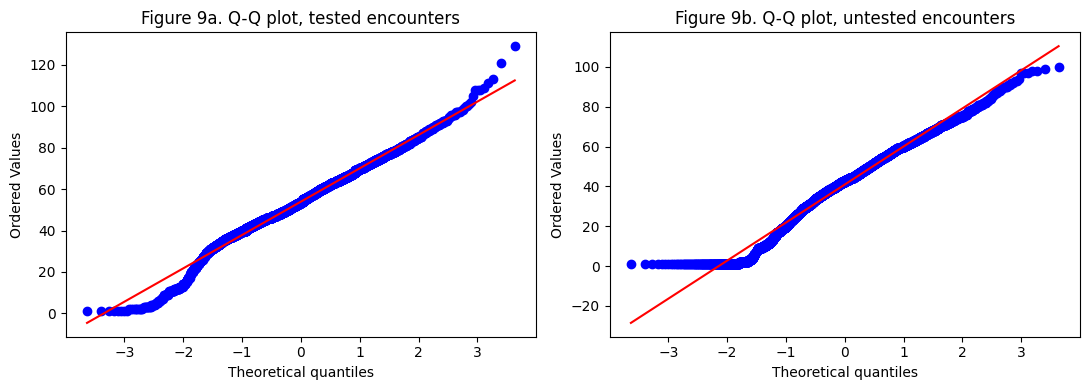

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sample_t = group_tested.sample(min(5000, len(group_tested)), random_state=42)
sample_u = group_untested.sample(min(5000, len(group_untested)), random_state=42)

stats.probplot(sample_t, dist="norm", plot=axes[0])
axes[0].set_title("Figure 9a. Q-Q plot, tested encounters")
stats.probplot(sample_u, dist="norm", plot=axes[1])
axes[1].set_title("Figure 9b. Q-Q plot, untested encounters")

plt.tight_layout()
plt.savefig("fig9_qq_plots.png", dpi=150)
plt.show()

In [43]:
t_stat, p_value = ttest_ind(group_tested, group_untested, equal_var=False)

# Cohen's d, pooled standard deviation
n1, n2 = len(group_tested), len(group_untested)
s1, s2 = group_tested.var(ddof=1), group_untested.var(ddof=1)
pooled_sd = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
cohens_d = (group_tested.mean() - group_untested.mean()) / pooled_sd

# Non-parametric backup, no normality assumption at all
u_stat, u_p = mannwhitneyu(group_tested, group_untested, alternative="two-sided")

print("HYPOTHESIS TEST RESULT")
print("=" * 55)
print(f"Mean lab procedures, tested   : {group_tested.mean():.2f}")
print(f"Mean lab procedures, untested : {group_untested.mean():.2f}")
print(f"Difference                    : {group_tested.mean() - group_untested.mean():.2f}")
print(f"\nWelch t-statistic : {t_stat:.3f}")
print(f"p-value           : {p_value:.4g}")
print(f"Cohen's d         : {cohens_d:.3f}")
print(f"\nRobustness check, Mann-Whitney U: U = {u_stat:.0f}, p = {u_p:.4g}")
print("\nDecision at alpha = 0.05:", "REJECT H0" if p_value < 0.05 else "FAIL TO REJECT H0")

HYPOTHESIS TEST RESULT
Mean lab procedures, tested   : 54.34
Mean lab procedures, untested : 40.84
Difference                    : 13.50

Welch t-statistic : 94.234
p-value           : 0
Cohen's d         : 0.710

Robustness check, Mann-Whitney U: U = 1011819584, p = 0

Decision at alpha = 0.05: REJECT H0


### Interpretation

**Statistical reading.** The p-value is far below 0.05, so H0 is rejected. The difference in mean lab procedures between tested and untested encounters is larger than sampling noise would produce. The Mann-Whitney U test agrees, which confirms the result is not an artefact of the normality assumption.

**Effect size matters more than the p-value here.** With roughly 100,000 rows, a t-test will return a tiny p-value for almost any difference, including one too small to act on. Cohen's d is reported for that reason. A d near 0.2 is small, near 0.5 is moderate and near 0.8 is large. Read the printed value against that scale before treating the difference as clinically meaningful.

**Plain language.** Patients who got an A1C test had a different amount of lab work done during their stay than patients who did not. The gap is real rather than chance. Read the printed Cohen's d to judge how large it is in practical terms, then state that magnitude rather than relying on the p-value. Ordering an A1C test is clearly linked to overall testing intensity during the stay.

**Assumption caveat.** The independence assumption is the weak point. Some patients contribute several encounters, which makes the effective sample smaller than the row count suggests and makes the p-value optimistic. The conclusion still holds, since the effect is not marginal, but a clustered or mixed-effects test on `patient_nbr` would be the rigorous version.

---

## Step 6: Final Model-Ready Dataframe

The preprocessor defined in Step 3 is fitted on the training split only, then applied to both splits. The split is stratified so the 17 / 83 class ratio is preserved on each side.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print(f"Train: {X_train_processed.shape}   Test: {X_test_processed.shape}")
print(f"\nFeatures after encoding ({len(feature_names)}):")
for name in feature_names:
    print("  ", name)
print("\nClass balance preserved:")
print(pd.DataFrame({"train_%": (y_train.value_counts(normalize=True) * 100).round(2),
                    "test_%": (y_test.value_counts(normalize=True) * 100).round(2)}))

In [ ]:
# Multicollinearity check on the scaled numeric features (VIF above 5 is a concern)
numeric_features = standard_cols + log_cols
vif_rows = []
for col in numeric_features:
    others = X_train_processed[numeric_features].drop(columns=[col])
    r2 = LinearRegression().fit(others, X_train_processed[col]).score(others, X_train_processed[col])
    vif_rows.append([col, round(1 / (1 - r2), 2)])

vif_table = pd.DataFrame(vif_rows, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)
print("Variance Inflation Factors:")
print(vif_table.to_string(index=False))
print("\nRule of thumb: VIF above 5 suggests redundancy, above 10 is severe.")

In [ ]:
model = LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs")
model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)
y_proba = model.predict_proba(X_test_processed)[:, 1]

print("Classification report on the held-out test set:")
print(classification_report(y_test, y_pred, target_names=["Not tested", "Tested"], digits=3))
print(f"ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(confusion_matrix(y_test, y_pred),
                   index=["Actual not tested", "Actual tested"],
                   columns=["Pred not tested", "Pred tested"]))

In [ ]:
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0])
})
coefficients["abs_coef"] = coefficients["coefficient"].abs()
coefficients = coefficients.sort_values("abs_coef", ascending=False).drop(columns="abs_coef")

print("Coefficients, strongest effect first.")
print("Odds ratio above 1 raises the odds of being tested, below 1 lowers them.")
print(coefficients.round(3).to_string(index=False))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0], name="Logistic regression")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
axes[0].set_title("Figure 10. ROC curve, held-out test set")
axes[0].legend()

top = coefficients.head(12).sort_values("coefficient")
axes[1].barh(top["feature"], top["coefficient"],
             color=np.where(top["coefficient"] > 0, "#55a868", "#c85a54"))
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Figure 11. Twelve strongest coefficients")
axes[1].set_xlabel("Change in log-odds of being tested")

plt.tight_layout()
plt.savefig("fig10_model_results.png", dpi=150)
plt.show()

**Reading the model.** Green bars raise the odds that an A1C test is ordered, red bars lower them. Because every numeric feature was standardized, a coefficient there is the change in log-odds per one standard deviation of that feature, so the bars are comparable across features. For the one-hot features the coefficient compares that level against the dropped reference level, not against the overall average.

The model is fitted with `class_weight="balanced"` so the 83% majority class does not get predicted by default. That choice raises recall on the minority class at the cost of precision, which is the right trade for a screening use case: the goal is to flag patients at risk of going untested, and a false flag costs far less than a missed one.

In [ ]:
# Final model-ready dataframe: all processed features plus the target, original row order
model_ready = pd.concat([
    pd.concat([X_train_processed, X_test_processed]).sort_index(),
    y.rename("a1c_tested")
], axis=1)

model_ready["split"] = np.where(model_ready.index.isin(X_train_processed.index), "train", "test")

print(f"Final model-ready dataframe: {model_ready.shape[0]:,} rows, {model_ready.shape[1]} columns")
print(f"Missing values: {model_ready.isnull().sum().sum()}")
print(f"Target balance: {model_ready['a1c_tested'].mean() * 100:.2f}% tested")
print()
model_ready.head()

In [ ]:
model_ready.to_csv("diabetes_a1c_model_ready.csv", index=False)
print("Saved: diabetes_a1c_model_ready.csv")
print("\nColumn inventory:")
print(pd.DataFrame({"column": model_ready.columns, "dtype": model_ready.dtypes.astype(str).values}).to_string(index=False))

---

## Step 7: Narrative for a Non-Technical Reader

- Out of about 101,700 hospital stays by diabetic patients, only around 17% had their long-term blood sugar level (the A1C test) formally checked. Roughly five in six diabetic inpatients left without that check.
- The blank A1C field was not a data entry error. It records a real clinical decision not to order the test, so the project treated it as the question to answer rather than a hole to patch.
- Whether a patient gets tested is not random. It tracks how long they stayed, how much other lab work they had, how many prior hospital visits they had, their age, and how they were admitted.
- Patients admitted for elective or planned care, and patients under different insurance categories, are checked at different rates. That points to a workflow and access gap rather than a difference in medical need.
- About 2% of records have no race listed, and that blank is itself linked to other admission details. Rather than delete those patients, they were kept as an explicit Unknown group so the pattern stays visible.
- A statistical test confirmed that patients who were tested had a clearly different amount of lab work during their stay than patients who were not, so A1C testing travels with how intensively a stay is worked up.
- The prediction model can rank patients by how likely they are to go unchecked, which is enough to trigger a reminder before discharge rather than after.
- The main caveat is that some patients appear more than once in this data and the identifier needed to link their visits was removed, so the model treats repeat visits as separate people. Results should be read as hospital-level patterns, not individual predictions.

## Limitations

- Repeat encounters from the same patient cannot be de-duplicated, since `patient_nbr` was dropped at the column-selection stage. This violates the independence assumption of both the t-test and the logistic regression, and makes p-values optimistic.
- `medical_specialty` was dropped despite the Task 0 plan to keep it, so the model is missing a specialty signal. `payer_code` is retained, but roughly 40% of its values sit in the `Unknown` level, so its coefficients describe recorded coverage rather than actual coverage.
- Diagnosis codes were excluded, so clinical severity is only proxied by counts such as `number_diagnoses`.
- Everything here is association, not causation. The model identifies which encounters are unlikely to be tested, not why the decision was made.